# Template notebook

It's good to start with an introduction, to set the scene and introduce your audience to the data, and the problem you're solving as a team.

<br>

## Libraries
As always, we'll start by importing the necessary libraries.

In [154]:
# It's good practice to add comments to explain your code 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, roc_auc_score

**Question / Task 1**

Insert context about question / task 1 here.

In [155]:
# load data
df = pd.read_csv('data/corona_tested_individuals_ver_006.english.csv',)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 278848 entries, 0 to 278847
Data columns (total 10 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   test_date            278848 non-null  object 
 1   cough                278596 non-null  float64
 2   fever                278596 non-null  float64
 3   sore_throat          278847 non-null  float64
 4   shortness_of_breath  278847 non-null  float64
 5   head_ache            278847 non-null  float64
 6   corona_result        278848 non-null  object 
 7   age_60_and_above     151528 non-null  object 
 8   gender               259285 non-null  object 
 9   test_indication      278848 non-null  object 
dtypes: float64(5), object(5)
memory usage: 21.3+ MB


/tmp/ipykernel_30/3925992429.py:2: DtypeWarning: Columns (7) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('data/corona_tested_individuals_ver_006.english.csv',)


In [156]:
# Add your code here
df['corona_result'].value_counts(normalize=True)*100

corona_result
negative    93.322168
positive     5.282089
other        1.395742
Name: proportion, dtype: float64

In [157]:
df.isnull().sum()

test_date                   0
cough                     252
fever                     252
sore_throat                 1
shortness_of_breath         1
head_ache                   1
corona_result               0
age_60_and_above       127320
gender                  19563
test_indication             0
dtype: int64

In [158]:
(df.isna().mean() * 100).round(2)

test_date               0.00
cough                   0.09
fever                   0.09
sore_throat             0.00
shortness_of_breath     0.00
head_ache               0.00
corona_result           0.00
age_60_and_above       45.66
gender                  7.02
test_indication         0.00
dtype: float64

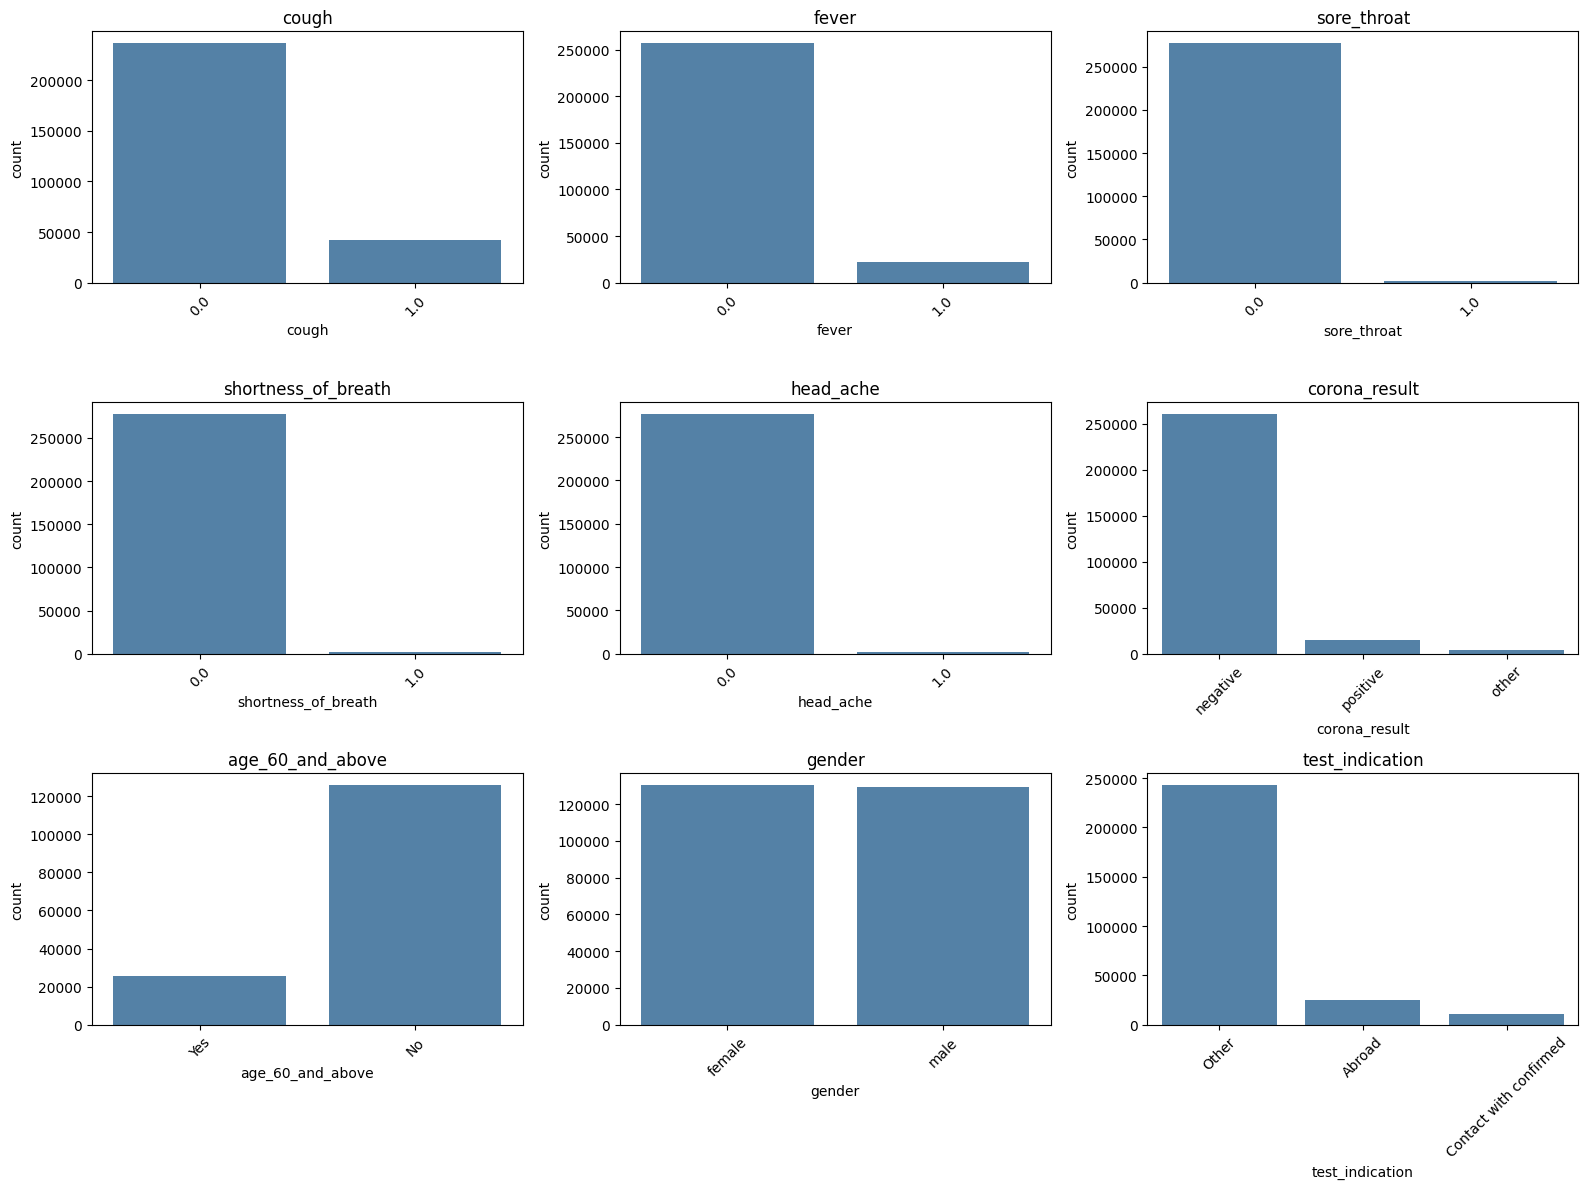

In [159]:
# Create a copy for exploration
eda_df = df.copy()

# Exclude test_date for now
columns = eda_df.columns.drop('test_date')

# Create a grid of charts
fig, axes = plt.subplots(3, 3, figsize=(16, 12))
axes = axes.flatten()

for i, col in enumerate(columns):
    sns.countplot(
        data=eda_df,
        x=col,
        ax=axes[i],
        color='steelblue'
    )
    axes[i].set_title(col)
    axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

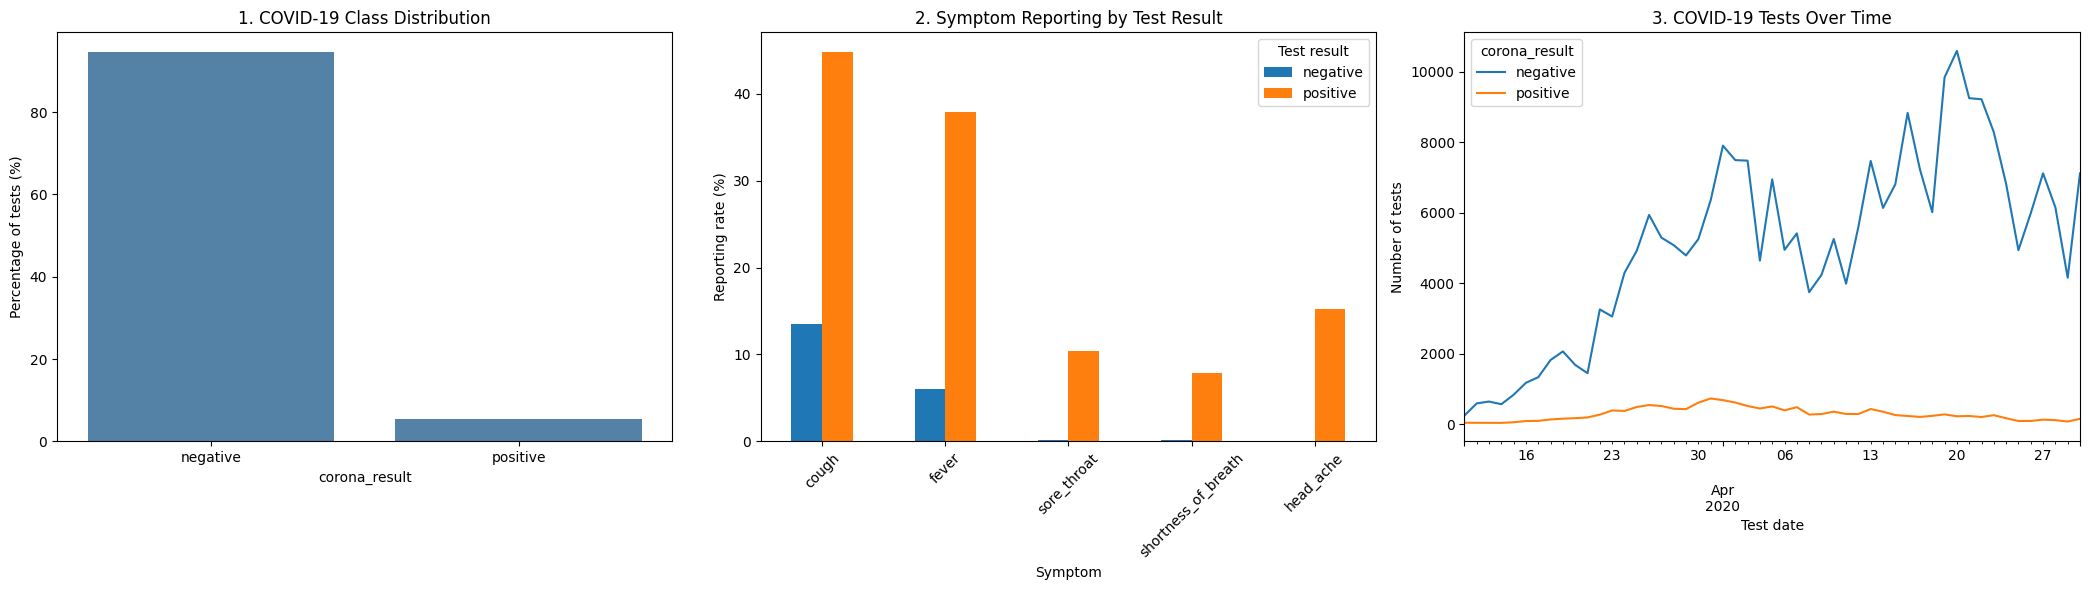

In [160]:
# Keep only confirmed positive and negative results
plot_df = df[
    df['corona_result'].isin(['positive', 'negative'])
].copy()

symptoms = [
    'cough', 'fever', 'sore_throat',
    'shortness_of_breath', 'head_ache'
]

# Convert symptoms to numeric values
for symptom in symptoms:
    plot_df[symptom] = pd.to_numeric(
        plot_df[symptom], errors='coerce'
    )

# Create three charts
fig, axes = plt.subplots(1, 3, figsize=(21, 6))

# 1. Class distribution
class_pct = (
    plot_df['corona_result']
    .value_counts(normalize=True)
    .reindex(['negative', 'positive']) * 100
)

sns.barplot(
    x=class_pct.index,
    y=class_pct.values,
    ax=axes[0],
    color='steelblue'
)
axes[0].set_title('1. COVID-19 Class Distribution')
axes[0].set_ylabel('Percentage of tests (%)')

# 2. Symptoms grouped by test result
symptom_rates = (
    plot_df.groupby('corona_result')[symptoms]
    .mean()
    .T
    .mul(100)
)

symptom_rates.plot(
    kind='bar',
    ax=axes[1]
)
axes[1].set_title('2. Symptom Reporting by Test Result')
axes[1].set_ylabel('Reporting rate (%)')
axes[1].set_xlabel('Symptom')
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend(title='Test result')

# 3. Testing patterns over time
plot_df['test_date'] = pd.to_datetime(
    plot_df['test_date'], errors='coerce'
)

daily = (
    plot_df.groupby(['test_date', 'corona_result'])
    .size()
    .unstack(fill_value=0)
)

daily.plot(
    ax=axes[2]
)
axes[2].set_title('3. COVID-19 Tests Over Time')
axes[2].set_ylabel('Number of tests')
axes[2].set_xlabel('Test date')

plt.tight_layout()
plt.show()

In [161]:
df_clean = df.copy()
#Ignore age 60 and above and gender columns
df_clean.drop(['test_date','age_60_and_above', 'gender',], axis=1, inplace=True)
#drops rows with null in other symptoms
df_clean.dropna(subset=['cough', 'fever', 'sore_throat', 'shortness_of_breath', 'head_ache'], inplace=True)

#corona result is our target. it has positive, negative and other. Other is abt 1%
#drop other for now
if 'other' in df_clean['corona_result'].unique():
    df_clean = df_clean[df_clean['corona_result'] != 'other']

df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 274702 entries, 0 to 278847
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   cough                274702 non-null  float64
 1   fever                274702 non-null  float64
 2   sore_throat          274702 non-null  float64
 3   shortness_of_breath  274702 non-null  float64
 4   head_ache            274702 non-null  float64
 5   corona_result        274702 non-null  object 
 6   test_indication      274702 non-null  object 
dtypes: float64(5), object(2)
memory usage: 16.8+ MB


In [162]:
# Categorise the features
df_cat = df_clean.copy()

#corona result is our target. it has positive, negative and other. make 1 for positive, 0 for the rest
df_cat["corona_result"] = (df_cat['corona_result']=='positive').astype(int)

encoded_df1 = df_cat.copy()
# test indication - categorise 'other', 'abroard' and 'contact with g
encoded_df1 = pd.get_dummies(
    df_cat,
    columns=['test_indication'],
    dtype=int
)

encoded_df1.head()

,cough,fever,sore_throat,shortness_of_breath,head_ache,corona_result,test_indication_Abroad,test_indication_Contact with confirmed,test_indication_Other
0,0.0,0.0,0.0,0.0,0.0,0,0,0,1
1,1.0,0.0,0.0,0.0,0.0,0,0,0,1
2,0.0,1.0,0.0,0.0,0.0,0,0,0,1
3,1.0,0.0,0.0,0.0,0.0,0,0,0,1
4,1.0,0.0,0.0,0.0,0.0,0,0,0,1


In [163]:
for col in [
    'cough',
    'fever',
    'sore_throat',
    'shortness_of_breath',
    'head_ache',
    'test_indication_Contact with confirmed'
]:
    print(f'\n{col}')
    print(encoded_df1.groupby(col)['corona_result'].value_counts(normalize=True))


cough
cough  corona_result
0.0    0                0.965204
       1                0.034796
1.0    0                0.841661
       1                0.158339
Name: proportion, dtype: float64

fever
fever  corona_result
0.0    0                0.963936
       1                0.036064
1.0    0                0.739964
       1                0.260036
Name: proportion, dtype: float64

sore_throat
sore_throat  corona_result
0.0          0                0.951722
             1                0.048278
1.0          1                0.806674
             0                0.193326
Name: proportion, dtype: float64

shortness_of_breath
shortness_of_breath  corona_result
0.0                  0                0.950461
                     1                0.049539
1.0                  1                0.751617
                     0                0.248383
Name: proportion, dtype: float64

head_ache
head_ache  corona_result
0.0        0                0.954231
           1                0.04576

In [164]:
# create a new column with the number of symptoms recorded = 0 (no symptoms) to 5 (all symptoms)
encoded_df = encoded_df1.copy()
encoded_df['n_symptoms'] = encoded_df[
    ['cough',
     'fever',
     'sore_throat',
     'shortness_of_breath',
     'head_ache']
].sum(axis=1)

# check the positivity rate of having different number of symptoms (mean)
encoded_df.groupby('n_symptoms')['corona_result'].agg(
    ['count', 'mean']
)

,count,mean
n_symptoms,,
0.0,225931,0.023397
1.0,31420,0.131286
2.0,15360,0.228255
3.0,1443,0.886348
4.0,455,0.898901
5.0,93,0.956989


In [165]:
'''
# create a column to flag where both fever and cough are present.
# This could be useful since in the SHAP analysis fever and cough are the strongest indicators for positivity

encoded_df['fever_cough'] = (
    (encoded_df['fever'] == 1) &
    (encoded_df['cough'] == 1)
).astype(int)

# check the positivity rate of having different number of symptoms (mean)
encoded_df.groupby('fever_cough')['corona_result'].agg(
    ['count', 'mean']
)
'''

"\n# create a column to flag where both fever and cough are present.\n# This could be useful since in the SHAP analysis fever and cough are the strongest indicators for positivity\n\nencoded_df['fever_cough'] = (\n    (encoded_df['fever'] == 1) &\n    (encoded_df['cough'] == 1)\n).astype(int)\n\n# check the positivity rate of having different number of symptoms (mean)\nencoded_df.groupby('fever_cough')['corona_result'].agg(\n    ['count', 'mean']\n)\n"

In [166]:
'''
# check if fever+cough is more predictive than just the number of symptoms
encoded_df.groupby(
    ['n_symptoms', 'fever_cough']
)['corona_result'].agg(
    ['count', 'mean']
)
'''

"\n# check if fever+cough is more predictive than just the number of symptoms\nencoded_df.groupby(\n    ['n_symptoms', 'fever_cough']\n)['corona_result'].agg(\n    ['count', 'mean']\n)\n"

In [167]:
'''
# check the positivity rate for every pair of symptoms
symptoms = [
    'cough',
    'fever',
    'sore_throat',
    'shortness_of_breath',
    'head_ache'
]

two_symptoms = encoded_df[encoded_df['n_symptoms'] == 2]

for s1 in symptoms:
    for s2 in symptoms:
        if s1 < s2:
            mask = (two_symptoms[s1] == 1) & (two_symptoms[s2] == 1)

            subset = two_symptoms[mask]

            if len(subset) > 0:
                print(
                    f'{s1} + {s2}:',
                    len(subset),
                    subset['corona_result'].mean()
                )
'''

"\n# check the positivity rate for every pair of symptoms\nsymptoms = [\n    'cough',\n    'fever',\n    'sore_throat',\n    'shortness_of_breath',\n    'head_ache'\n]\n\ntwo_symptoms = encoded_df[encoded_df['n_symptoms'] == 2]\n\nfor s1 in symptoms:\n    for s2 in symptoms:\n        if s1 < s2:\n            mask = (two_symptoms[s1] == 1) & (two_symptoms[s2] == 1)\n\n            subset = two_symptoms[mask]\n\n            if len(subset) > 0:\n                print(\n                    f'{s1} + {s2}:',\n                    len(subset),\n                    subset['corona_result'].mean()\n                )\n"

In [168]:
'''
# create a column to flag if there is haed-ache together with another symptom
encoded_df['headache_plus'] = (
    encoded_df[
        ['cough',
         'fever',
         'sore_throat',
         'shortness_of_breath']
    ].sum(axis=1) > 0
) & (encoded_df['head_ache'] == 1)


encoded_df.groupby(
    ['headache_plus']
)['corona_result'].agg(
    ['count', 'mean']
)
'''

"\n# create a column to flag if there is haed-ache together with another symptom\nencoded_df['headache_plus'] = (\n    encoded_df[\n        ['cough',\n         'fever',\n         'sore_throat',\n         'shortness_of_breath']\n    ].sum(axis=1) > 0\n) & (encoded_df['head_ache'] == 1)\n\n\nencoded_df.groupby(\n    ['headache_plus']\n)['corona_result'].agg(\n    ['count', 'mean']\n)\n"

In [169]:
'''
# create a column to flag presence of high-risk symptoms
high_risk_symptoms = [
    'head_ache',
    'sore_throat',
    'shortness_of_breath'
]

encoded_df['n_high_risk_symptoms'] = (
    encoded_df[high_risk_symptoms]
    .sum(axis=1)
)

# check how predictive it is
encoded_df.groupby(
    'n_high_risk_symptoms'
)['corona_result'].agg(['count','mean'])
'''

"\n# create a column to flag presence of high-risk symptoms\nhigh_risk_symptoms = [\n    'head_ache',\n    'sore_throat',\n    'shortness_of_breath'\n]\n\nencoded_df['n_high_risk_symptoms'] = (\n    encoded_df[high_risk_symptoms]\n    .sum(axis=1)\n)\n\n# check how predictive it is\nencoded_df.groupby(\n    'n_high_risk_symptoms'\n)['corona_result'].agg(['count','mean'])\n"

In [170]:
# create column to check symptoms count vs contact with confirmed
encoded_df.groupby(
    ['test_indication_Contact with confirmed',
     'n_symptoms']
)['corona_result'].agg(['count','mean'])

count      mean
test_indication_Contact with confirmed n_symptoms                  
0                                      0.0         222457  0.011935
                                       1.0          27576  0.070097
                                       2.0          13084  0.139636
                                       3.0            811  0.860666
                                       4.0            253  0.873518
                                       5.0             54  0.962963
1                                      0.0           3474  0.757340
                                       1.0           3844  0.570239
                                       2.0           2276  0.737698
                                       3.0            632  0.919304
                                       4.0            202  0.930693
                                       5.0             39  0.948718

In [171]:
encoded_df.groupby(
    'test_indication_Contact with confirmed'
)['n_symptoms'].agg(
    ['count', 'mean', 'median']
)

,count,mean,median
test_indication_Contact with confirmed,,,
0,264235,0.217454,0.0
1,10467,1.079106,1.0


In [172]:
encoded_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 274702 entries, 0 to 278847
Data columns (total 10 columns):
 #   Column                                  Non-Null Count   Dtype  
---  ------                                  --------------   -----  
 0   cough                                   274702 non-null  float64
 1   fever                                   274702 non-null  float64
 2   sore_throat                             274702 non-null  float64
 3   shortness_of_breath                     274702 non-null  float64
 4   head_ache                               274702 non-null  float64
 5   corona_result                           274702 non-null  int64  
 6   test_indication_Abroad                  274702 non-null  int64  
 7   test_indication_Contact with confirmed  274702 non-null  int64  
 8   test_indication_Other                   274702 non-null  int64  
 9   n_symptoms                              274702 non-null  float64
dtypes: float64(6), int64(4)
memory usage: 23.1 MB


In [173]:
#use a simple decision tree for baseline model

y = encoded_df['corona_result']
X = encoded_df.drop('corona_result', axis=1)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print('Training:\n',y_train.value_counts(normalize=True))
print('\nTest:\n',y_test.value_counts(normalize=True))

Training:
 corona_result
0    0.94651
1    0.05349
Name: proportion, dtype: float64

Test:
 corona_result
0    0.946506
1    0.053494
Name: proportion, dtype: float64


In [174]:
#Fit to simple decision tree
dtc = DecisionTreeClassifier(class_weight='balanced',random_state=42)
dtc.fit(X_train, y_train)

DecisionTreeClassifier(class_weight='balanced', random_state=42)

In [175]:
y_pred = dtc.predict(X_test)
y_prob = dtc.predict_proba(X_test)[:, 1]

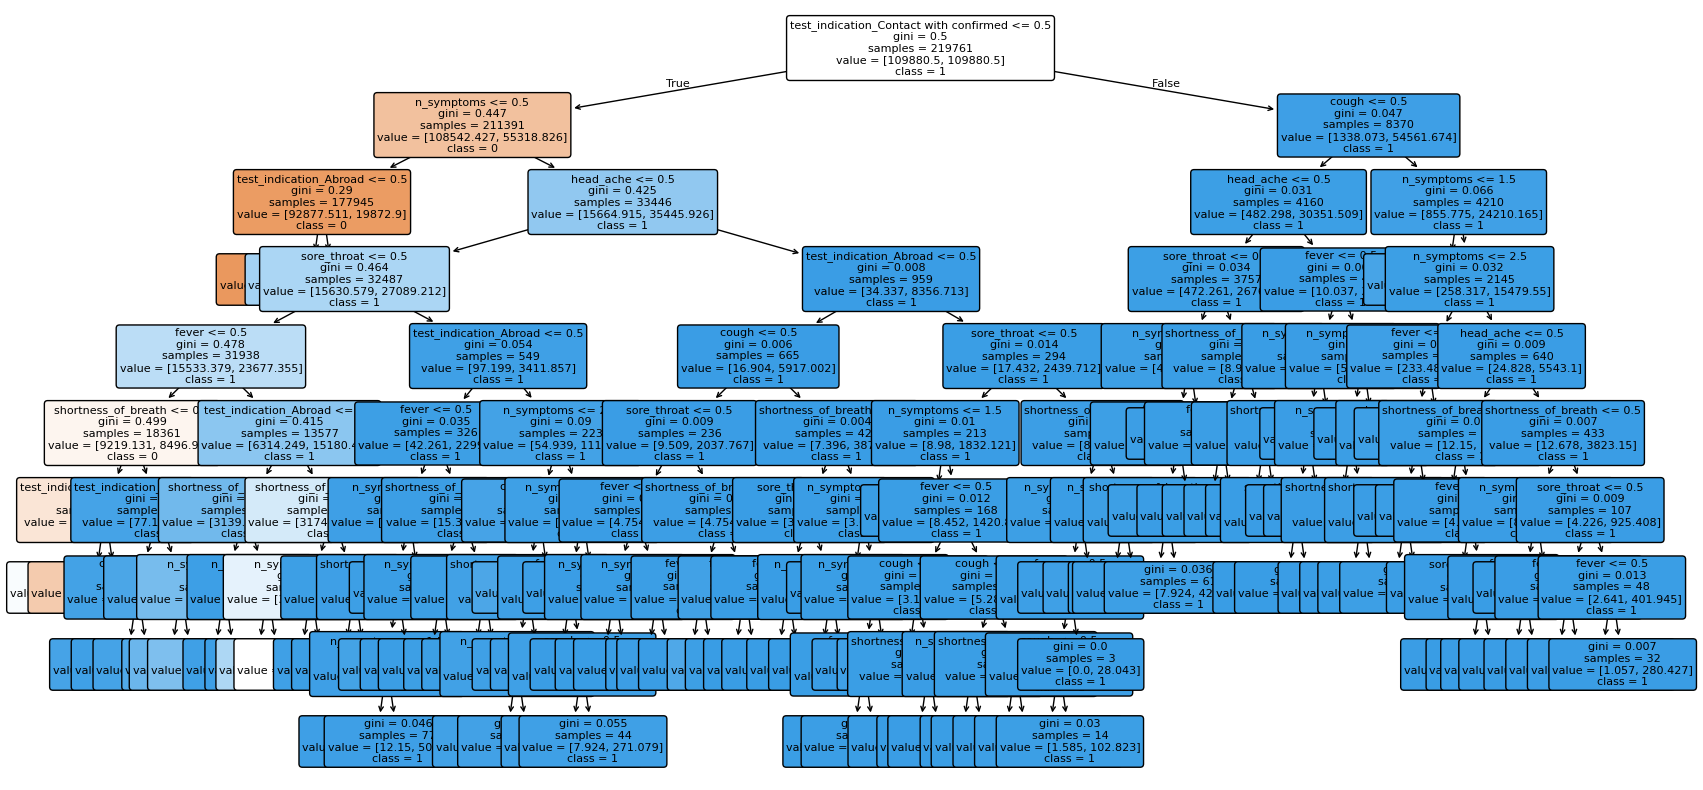

In [176]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(20,10))
plot_tree(
    dtc,
    filled=True,
    feature_names=X_train.columns,
    class_names=[str(c) for c in dtc.classes_],
    rounded=True,
    fontsize=8
)

plt.show()

In [177]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

print('Accuracy :', accuracy_score(y_test, y_pred))
print('Precision:', precision_score(y_test, y_pred))
print('Recall   :', recall_score(y_test, y_pred))
print('F1       :', f1_score(y_test, y_pred))
print('ROC AUC  :', roc_auc_score(y_test, y_prob))

Accuracy : 0.8933219271582242
Precision: 0.3088697017268446
Recall   : 0.8033344675059544
F1       : 0.44618728148918074
ROC AUC  : 0.8945130018882332


In [178]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.99      0.90      0.94     52002
           1       0.31      0.80      0.45      2939

    accuracy                           0.89     54941
   macro avg       0.65      0.85      0.69     54941
weighted avg       0.95      0.89      0.91     54941



In [179]:
print('Tree depth:', dtc.get_depth())
print('Number of leaves:', dtc.get_n_leaves())

Tree depth: 9
Number of leaves: 94


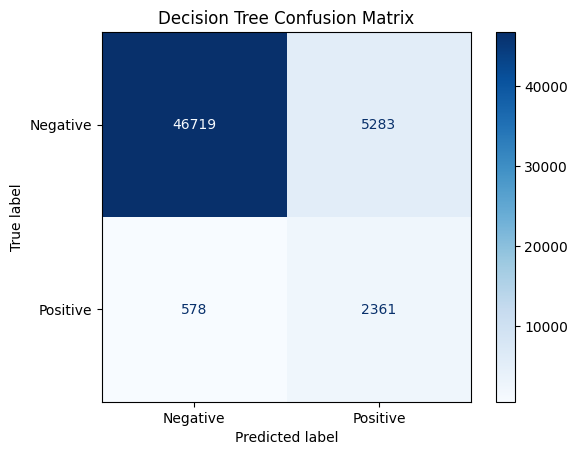

In [180]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Negative', 'Positive']
)

disp.plot(cmap='Blues')
plt.title('Decision Tree Confusion Matrix')
plt.show()

In [181]:
'''
The model identified only 53% of the people who were actually positive.
Put another way, of 2,939 actual positives:
it correctly detected 1,571
it missed 1,368
so it's missing roughly 47% of the positive cases
 Correctly identified 1571 positive (1), 1358 were identified as negative when actually positive.
We want to improve this so catch more true positives.
'''

"\nThe model identified only 53% of the people who were actually positive.\nPut another way, of 2,939 actual positives:\nit correctly detected 1,571\nit missed 1,368\nso it's missing roughly 47% of the positive cases\n Correctly identified 1571 positive (1), 1358 were identified as negative when actually positive.\nWe want to improve this so catch more true positives.\n"

In [182]:
import sys
!{sys.executable} -m pip install shap

Defaulting to user installation because normal site-packages is not writeable
  Using cached numpy-2.4.6-cp311-cp311-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (6.6 kB)
  Using cached numpy-2.2.6-cp311-cp311-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (62 kB)
Using cached numpy-2.2.6-cp311-cp311-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (16.8 MB)
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ydata-profiling 4.12.0 requires numpy<2.2,>=1.16.0, but you have numpy 2.2.6 which is incompatible.
catboost 1.2.7 requires numpy<2.0,>=1.16.0, but you have numpy 2.2.6 which is incompatible.

[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [183]:
import sys
print(sys.executable)

import site
print(site.getusersitepackages())

print('\n'.join(sys.path))

sys.path.insert(0, '/home/kate/.local/lib/python3.11/site-packages')

/usr/local/bin/python3.11
/home/kate/.local/lib/python3.11/site-packages
/home/kate/.local/lib/python3.11/site-packages
/home/kate/.local/lib/python3.11/site-packages
/home/kate/l7-hackathon/lessons
/home/kate/l7-hackathon/lessons

/kas/kloud/notebook/python3.11/site-packages
/kas/python_stacks/python_311_data_science/site-packages
/usr/local/lib/python311.zip
/usr/local/lib/python3.11
/usr/local/lib/python3.11/lib-dynload
/usr/local/lib/python3.11/site-packages
/kas/kloud/notebook/python3.11/site-packages/IPython/extensions
/home/kate/.ipython
/home/kate/.local/bin
/home/kate/.local/lib/python3.*/site-packages


In [184]:
'''Explore with SHAP'''
# Create a SHAP explainer for your trained decision tree
explainer = shap.TreeExplainer(dtc)

# Select a sample of observations to explain
X_sample = X_test.sample(
    n=min(500, len(X_test)),
    random_state=42
)

# Calculate SHAP values
shap_values = explainer(X_sample)

print("SHAP values shape:", shap_values.values.shape)

SHAP values shape: (500, 9, 2)


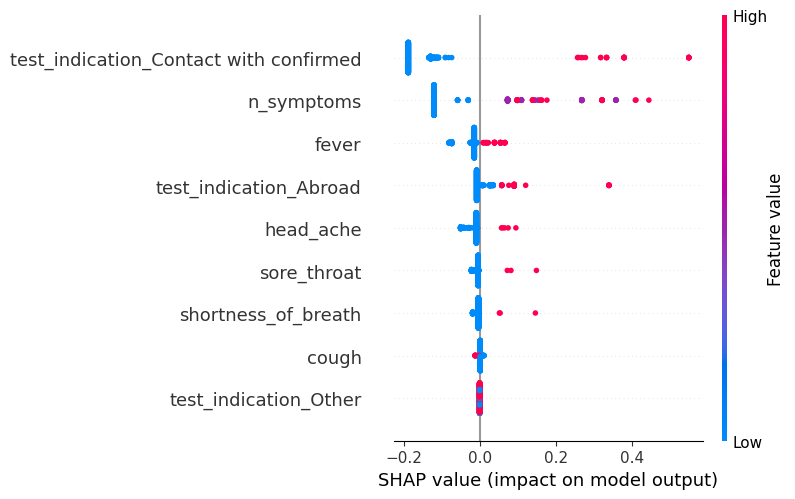

In [185]:
import numpy as np

# Find the index of the positive class
positive_class = (
    list(dtc.classes_).index(1)
    if 1 in dtc.classes_
    else list(dtc.classes_).index('positive')
)

# Select positive-class SHAP values if both classes are present
if shap_values.values.ndim == 3:
    positive_shap = shap_values[:, :, positive_class]
else:
    positive_shap = shap_values

# Plot feature contributions
shap.summary_plot(
    positive_shap.values,
    X_sample,
    feature_names=X_sample.columns
)

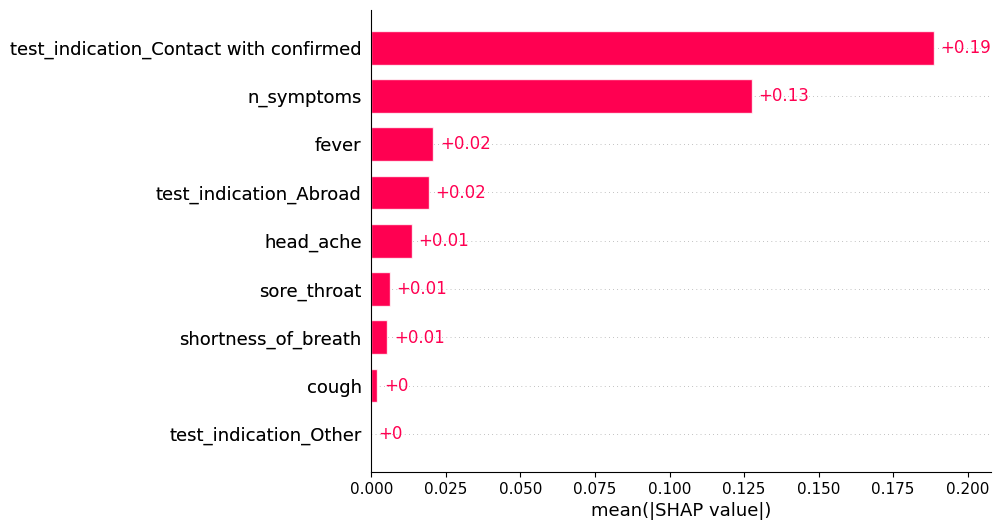

In [186]:
shap.plots.bar(positive_shap, max_display=10)